# Tahap 2A: Transformasi Varians & Uji Stasioneritas Awal
**Penanggung Jawab:** Maulana Naufal H  
**Mata Kuliah:** Analisis Data Timeseries — Sains Data  

---

### Tujuan Pengerjaan:
1. **Evaluasi Kestabilan Varians:** Memeriksa hubungan mean-varians, menguji parameter $\lambda$ Box-Cox, dan membandingkan skala asli vs logaritma.
2. **Uji Stasioneritas Awal (Level):** Menjalankan uji ADF dan KPSS pada deret level (skala asli dan skala log) sebagai dasar penentuan orde diferensiasi ($d$ dan $D$) untuk Tahap 2B (Aldo).


In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import boxcox, boxcox_llf
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")

# Path data
ROOT = Path.cwd().resolve()
if (ROOT / "data" / "processed").exists():
    DATA_DIR = ROOT / "data" / "processed"
elif Path(r"C:\Users\Lenovo\Downloads\Analisis Data Time Series\data\processed").exists():
    DATA_DIR = Path(r"C:\Users\Lenovo\Downloads\Analisis Data Time Series\data\processed")
else:
    DATA_DIR = Path(r"C:\Users\Lenovo\.gemini\antigravity\scratch\adt-project\data\processed")

# Visualisasi
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "figure.autolayout": True
})

# Load dataset mingguan PM2.5 Surakarta (hasil pra-pemrosesan Kunto)
df = pd.read_csv(DATA_DIR / "pm25_surakarta_weekly_model.csv", parse_dates=["week_start"])
series = df.set_index("week_start")["pm25"].asfreq("7D")

# Partisi: 104 minggu train (2 siklus musiman tahunan) dan 12 minggu test
train = series.iloc[:-12]
test = series.iloc[-12:]

print(f"Total deret : {len(series)} minggu ({series.index.min().strftime('%Y-%m-%d')} s.d. {series.index.max().strftime('%Y-%m-%d')})")
print(f"Data latih  : {len(train)} minggu ({train.index.min().strftime('%Y-%m-%d')} s.d. {train.index.max().strftime('%Y-%m-%d')})")
print(f"Data uji    : {len(test)} minggu ({test.index.min().strftime('%Y-%m-%d')} s.d. {test.index.max().strftime('%Y-%m-%d')})")


Total deret : 116 minggu (2022-08-08 s.d. 2024-10-21)
Data latih  : 104 minggu (2022-08-08 s.d. 2024-07-29)
Data uji    : 12 minggu (2024-08-05 s.d. 2024-10-21)


## 1. Diagnosis Kestabilan Varians
Sebelum melakukan diferensiasi rataan, kestabilan varians diuji terlebih dahulu untuk melihat apakah variabilitas data membesar seiring naiknya level rata-rata (heteroskedastisitas).
* **Uji visual:** Scatter plot antara *rolling mean* dan *rolling standard deviation* (window = 8 minggu).
* **Uji segmen:** Perbandingan varians antarsegmen semester (26 minggu).


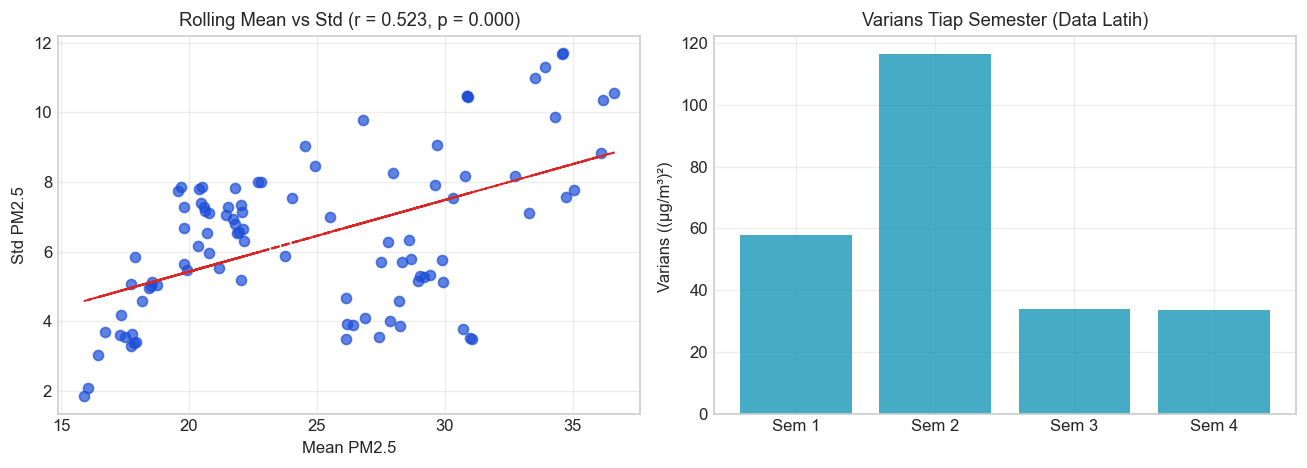

,Semester,Mean,Std,Varians,CV
0,Sem 1 (Aug 22 - Jan 23),22.89,7.61,57.87,0.33
1,Sem 2 (Feb 23 - Jul 23),28.49,10.79,116.51,0.38
2,Sem 3 (Aug 23 - Jan 24),19.80,5.82,33.87,0.29
3,Sem 4 (Feb 24 - Jul 24),27.29,5.80,33.63,0.21


In [2]:
roll_mean = train.rolling(8, center=True).mean().dropna()
roll_std = train.rolling(8, center=True).std().dropna()
corr, p_corr = stats.pearsonr(roll_mean, roll_std)

# Varians per semester (26 minggu)
sem_stats = []
for i in range(4):
    seg = train.iloc[i * 26:(i + 1) * 26]
    sem_stats.append({
        "Semester": f"Sem {i+1} ({seg.index.min().strftime('%b %y')} - {seg.index.max().strftime('%b %y')})",
        "Mean": seg.mean(),
        "Std": seg.std(),
        "Varians": seg.var(),
        "CV": seg.std() / seg.mean()
    })
df_sem = pd.DataFrame(sem_stats)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(roll_mean, roll_std, color="#1d4ed8", alpha=0.7)
m, b = np.polyfit(roll_mean, roll_std, 1)
ax[0].plot(roll_mean, m * roll_mean + b, color="#dc2626", linestyle="--", lw=1.2)
ax[0].set_title(f"Rolling Mean vs Std (r = {corr:.3f}, p = {p_corr:.3f})")
ax[0].set_xlabel("Mean PM2.5")
ax[0].set_ylabel("Std PM2.5")

ax[1].bar([f"Sem {i+1}" for i in range(4)], df_sem["Varians"], color="#0891b2", alpha=0.75)
ax[1].set_title("Varians Tiap Semester (Data Latih)")
ax[1].set_ylabel("Varians ((µg/m³)²) ")
plt.tight_layout()
plt.show()

display(df_sem.round(2))


## 2. Uji Parameter Box-Cox & Perbandingan Skala
Transformasi Box-Cox didefinisikan sebagai:
$$w_t = \begin{cases} \frac{y_t^\lambda - 1}{\lambda}, & \lambda \neq 0 \\[6pt] \ln(y_t), & \lambda = 0 \end{cases}$$

Untuk menguji apakah $\lambda$ berbeda secara signifikan dari 1 (deret asli) atau 0 (logaritma), digunakan uji Likelihood Ratio (LR):
$$LR = 2 [\ell(\hat{\lambda}) - \ell(\lambda_0)] \sim \chi^2_{(1)}$$


Uji Hipotesis Parameter Lambda:


,Hipotesis (H0),Nilai λ,Log-Likelihood,LR Stat,p-value,Kesimpulan Statistik
0,λ = 1 (Deret Asli),1.0000,-221.09,9.632,1.9126e-03,Tolak H0 (λ=1 tidak didukung)
1,λ = 0 (Transformasi Log),0.0000,-216.40,0.259,0.6108,Gagal tolak H0 (λ=0 didukung)
2,λ optimal (MLE),0.1387,-216.27,0.000,-,Nilai Optimal


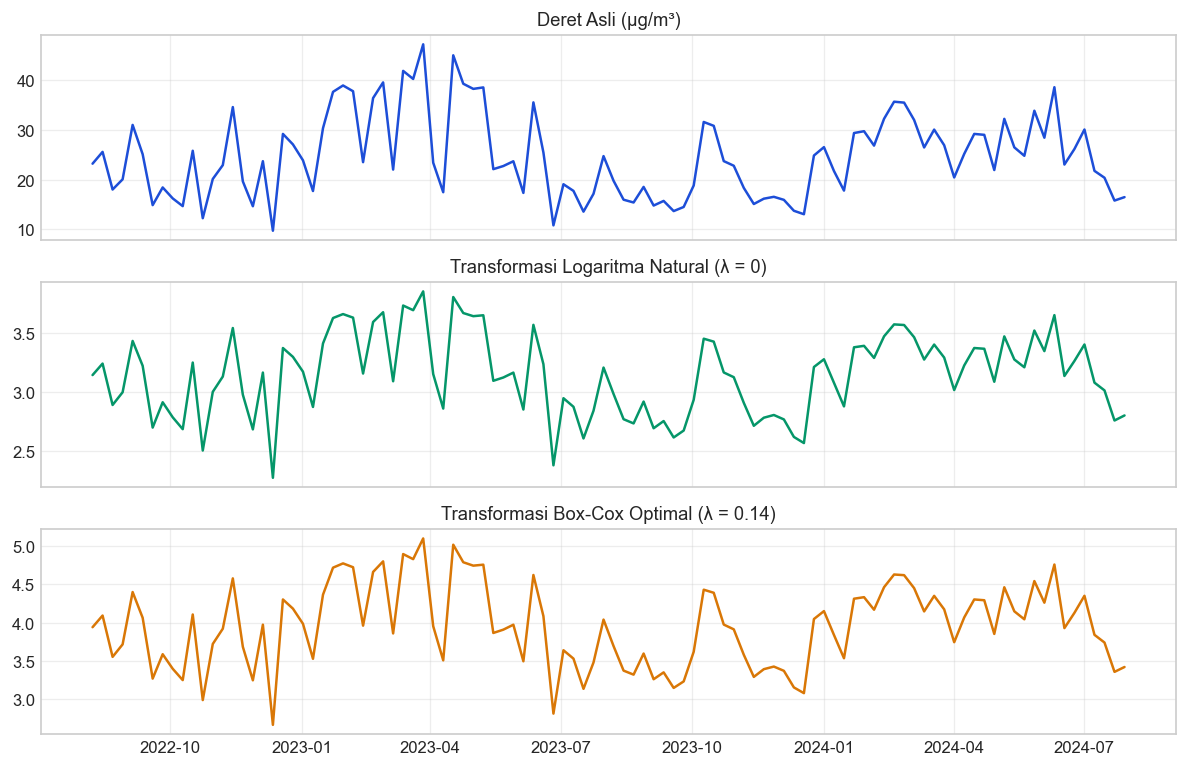

Perbandingan Stabilitas Varians Antar-Semester:


,Skala,Varians Total,Rasio Varians Max/Min Semester
0,Deret Asli,70.909,3.464
1,Log,0.120,3.226
2,Box-Cox (λ=0.14),0.284,3.231


In [3]:
train_bc, lam_opt = boxcox(train)
train_log = np.log(train)

# Likelihood Ratio Test
llf_opt = boxcox_llf(lam_opt, train)
llf_1 = boxcox_llf(1.0, train)
llf_0 = boxcox_llf(0.0, train)

lr_1 = 2 * (llf_opt - llf_1)
p_1 = 1 - stats.chi2.cdf(lr_1, df=1)

lr_0 = 2 * (llf_opt - llf_0)
p_0 = 1 - stats.chi2.cdf(lr_0, df=1)

df_lr = pd.DataFrame({
    "Hipotesis (H0)": ["λ = 1 (Deret Asli)", "λ = 0 (Transformasi Log)", "λ optimal (MLE)"],
    "Nilai λ": [1.0, 0.0, round(lam_opt, 4)],
    "Log-Likelihood": [round(llf_1, 2), round(llf_0, 2), round(llf_opt, 2)],
    "LR Stat": [round(lr_1, 3), round(lr_0, 3), 0.0],
    "p-value": [f"{p_1:.4e}", f"{p_0:.4f}", "-"],
    "Kesimpulan Statistik": [
        "Tolak H0 (λ=1 tidak didukung)" if p_1 < 0.05 else "Gagal tolak H0",
        "Gagal tolak H0 (λ=0 didukung)" if p_0 >= 0.05 else "Tolak H0",
        "Nilai Optimal"
    ]
})
print("Uji Hipotesis Parameter Lambda:")
display(df_lr)

# Plot perbandingan bentuk deret
fig, ax = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True)
ax[0].plot(train.index, train.values, color="#1d4ed8")
ax[0].set_title("Deret Asli (µg/m³)")

ax[1].plot(train.index, train_log.values, color="#059669")
ax[1].set_title("Transformasi Logaritma Natural (λ = 0)")

ax[2].plot(train.index, train_bc, color="#d97706")
ax[2].set_title(f"Transformasi Box-Cox Optimal (λ = {lam_opt:.2f})")
plt.tight_layout()
plt.show()

# Rasio varians max/min semester
def var_ratio(arr):
    v = [arr[i * 26:(i + 1) * 26].var() for i in range(4)]
    return max(v) / min(v)

df_comp = pd.DataFrame({
    "Skala": ["Deret Asli", "Log", f"Box-Cox (λ={lam_opt:.2f})"],
    "Varians Total": [train.var(), train_log.var(), np.var(train_bc)],
    "Rasio Varians Max/Min Semester": [var_ratio(train.values), var_ratio(train_log.values), var_ratio(train_bc)]
})
print("Perbandingan Stabilitas Varians Antar-Semester:")
display(df_comp.round(3))


## 3. Pembahasan Temuan & Dua Opsi Pemodelan

Berdasarkan hasil analisis varians dan uji Box-Cox, dirumuskan **dua opsi pemodelan** yang dapat dipilih oleh tim:

### Opsi 1: Pemodelan pada Deret Asli (Rekomendasi Utama / Baseline)
* **Kelebihan & Alasan:**
  1. **Interpretabilitas Satuan Fisik:** Nilai deret, metrik evaluasi (RMSE/MAE), dan peramalan tetap berada dalam satuan baku mutu udara ambien yang intuitif (µg/m³).
  2. **Konsistensi dengan Musiman Aditif:** Dekomposisi STL Kunto (Tahap 1) menunjukkan sifat musiman aditif dominan ($F_s = 0,927$). Mempertahankan skala asli menjaga struktur aditif tersebut.
  3. **Tanpa Bias Retransformasi:** Tidak memerlukan transformasi balik non-linear (menghindari bias *Jensen's Inequality*).
* **Konsekuensi:** Varians antarmusim tetap memiliki selisih (rasio semester = 3,46) yang bersumber dari siklus iklim alami (kemarau vs hujan).

---

### Opsi 2: Pemodelan pada Deret Logaritma (Alternatif Matematis)
* **Kelebihan & Alasan:**
  1. **Dukungan Uji Formal Box-Cox:** Uji rasio likelihood secara signifikan menolak deret asli $\lambda = 1$ ($p = 0,0019$) dan menerima transformasi log $\lambda = 0$ ($p = 0,6108$).
  2. **Jaminan Nilai Non-Negatif:** Skala logaritma secara matematis menjamin nilai konsentrasi polusi selalu bernilai positif setelah di-eksponensialkan (mencegah batas bawah ramalan negatif).
* **Konsekuensi:** Tahap peramalan akhir (Trisha) wajib menerapkan *inverse-transform* $\exp(\cdot)$ disertai koreksi bias untuk menghitung rata-rata konsentrasi polutan.


## 4. Uji Stasioneritas Awal Deret Level (ADF & KPSS)
Uji stasioneritas awal dilakukan menggunakan dua uji komplementer:
* **ADF (Augmented Dickey-Fuller):**  
  $H_0$: Deret memiliki akar unit / tidak stasioner.  
  $H_1$: Deret stasioner.  
  (Tolak $H_0$ jika $p < 0,05$).
* **KPSS (Kwiatkowski-Phillips-Schmidt-Shin):**  
  $H_0$: Deret stasioner di sekitar konstan.  
  $H_1$: Deret memiliki akar unit / tidak stasioner.  
  (Tolak $H_0$ jika $p < 0,05$).

Pengujian dilakukan pada data latih ($n=104$) dan data penuh ($n=116$), baik untuk deret asli maupun deret log.


In [4]:
series_log = np.log(series)

def audit_stationarity(ts_data, label):
    adf = adfuller(ts_data, autolag="AIC")
    kp = kpss(ts_data, regression="c", nlags="auto")
    return [
        {
            "Skala": label,
            "Uji": "ADF",
            "Statistik": round(adf[0], 4),
            "p-value": round(adf[1], 4),
            "Kritis 1%": round(adf[4]["1%"], 3),
            "Kritis 5%": round(adf[4]["5%"], 3),
            "Lag": int(adf[2]),
            "n": int(adf[3]),
            "Kesimpulan": "Stasioner (Tolak H0)" if adf[1] < 0.05 else "Tidak stasioner (Ada unit root)"
        },
        {
            "Skala": label,
            "Uji": "KPSS",
            "Statistik": round(kp[0], 4),
            "p-value": round(kp[1], 4),
            "Kritis 1%": round(kp[3]["1%"], 3),
            "Kritis 5%": round(kp[3]["5%"], 3),
            "Lag": int(kp[2]),
            "n": len(ts_data),
            "Kesimpulan": "Tidak stasioner (Tolak H0)" if kp[1] < 0.05 else "Stasioner (Gagal tolak H0)"
        }
    ]

results = []
results.extend(audit_stationarity(train, "Deret Asli - Data Latih (n=104)"))
results.extend(audit_stationarity(series, "Deret Asli - Data Penuh (n=116)"))
results.extend(audit_stationarity(train_log, "Deret Log - Data Latih (n=104)"))
results.extend(audit_stationarity(series_log, "Deret Log - Data Penuh (n=116)"))

df_stat_all = pd.DataFrame(results)
display(df_stat_all)


,Skala,Uji,Statistik,p-value,Kritis 1%,Kritis 5%,Lag,n,Kesimpulan
0,Deret Asli - Data Latih (n=104),ADF,-3.1439,0.0235,-3.497,-2.891,2,101,Stasioner (Tolak H0)
1,Deret Asli - Data Latih (n=104),KPSS,0.1324,0.1000,0.739,0.463,4,104,Stasioner (Gagal tolak H0)
2,Deret Asli - Data Penuh (n=116),ADF,-2.2078,0.2034,-3.491,-2.888,4,111,Tidak stasioner (Ada unit root)
3,Deret Asli - Data Penuh (n=116),KPSS,0.1608,0.1000,0.739,0.463,5,116,Stasioner (Gagal tolak H0)
4,Deret Log - Data Latih (n=104),ADF,-3.1655,0.0221,-3.497,-2.891,2,101,Stasioner (Tolak H0)
5,Deret Log - Data Latih (n=104),KPSS,0.1361,0.1000,0.739,0.463,4,104,Stasioner (Gagal tolak H0)
6,Deret Log - Data Penuh (n=116),ADF,-3.1638,0.0222,-3.490,-2.887,2,113,Stasioner (Tolak H0)
7,Deret Log - Data Penuh (n=116),KPSS,0.1374,0.1000,0.739,0.463,5,116,Stasioner (Gagal tolak H0)


## 5. Ringkasan & Panduan untuk Tahap 2B (Aldo)

### Hasil Uji Stasioneritas Level:
* **Deret Asli:** Pada data penuh ($n=116$), ADF bernilai $-2,2078$ ($p = 0,2034 > 0,05$), mengonfirmasi adanya akar unit / tidak stasioner. Pada data latih ($n=104$), ADF menghasilkan $p = 0,0235$, namun ACF meluruh lambat (*slow decay*), menandakan persistensi tinggi.
* **Deret Log:** Pada data penuh dan latih, ADF menolak akar unit ($p \approx 0,022$). Uji KPSS pada kedua skala gagal menolak $H_0$ ($p \ge 0,10$).

---

### Panduan Teknis untuk Aldo (Tahap 2B):
Tergantung opsi yang disepakati oleh tim:

1. **Jika Memilih Opsi 1 (Deret Asli):**
   * Lakukan diferensiasi pertama non-musiman:
     $$\Delta y_t = y_t - y_{t-1} \quad (d = 1)$$
   * Uji ulang ADF & KPSS pada deret $\Delta y_t$ untuk memastikan stasioneritas rataan.

2. **Jika Memilih Opsi 2 (Deret Log):**
   * Lakukan diferensiasi pertama pada deret logaritma:
     $$\Delta \ln(y_t) = \ln(y_t) - \ln(y_{t-1}) \quad (d = 1)$$
   * Lanjutkan pemodelan AR/MA/ARMA dari deret log stasioner tersebut.

3. **Catatan Diferensiasi Musiman ($D$) untuk Kedua Opsi:**
   * Karena panjang data latih hanya terdiri dari 104 minggu ($2$ siklus $s=52$), penerapan diferensiasi musiman ($D = 1$) akan menghilangkan 52 observasi awal dan berisiko *over-differencing*.
   * Disarankan menetapkan **$D = 0$** dan menangkap osilasi musiman melalui parameter musiman SARIMA pada tahap pemodelan Raihan.
